# 모듈 2. AI 정보 추출: 텀시트를 데이터로

**목표**
1. 텀시트 데이터 사전(스키마)을 정의한다.
2. Claude로 **정답셋(gold set)**을 만들고 사람이 검수한다.
3. 전량에 돌릴 **규칙 기반 추출기**를 정답셋으로 채점한다.
4. Claude와 함께 오류를 분석하고 추출기를 개선한다.

**산출물**: `gold/*.json` (정답셋 27건), `data/interim/termsheets.parquet` (확정본 전체 추출 결과)

## 1. 왜 "라벨러 + 코더" 2단계인가

JPM 하나만 해도 확정본이 한 해 1만 건 이상입니다. 방법별로 비교하면 이렇습니다.

| 방법 | 정확도 | 규모 | 비용·재현성 | 감사 가능성 |
|---|---|---|---|---|
| ① Claude가 전량을 직접 읽기 | 높음 | 대화창으로는 비현실적 | 매번 사용량 소모, 결과가 조금씩 달라짐 | 근거 문장을 남기면 가능 |
| ② 정규식만 손으로 작성 | 형식이 바뀌면 급락 | 무제한 | 무료·결정적 | 높음 |
| ③ **Claude = 정답 라벨러 + 코딩 파트너** | ①에 근접하도록 반복 개선 | 무제한 | 무료·결정적 | 높음 |

③에서 Claude는 두 가지 일을 합니다.
- 소수 문서를 정밀하게 읽어 **정답**을 만든다. (사람은 근거 문장으로 검수)
- 정답셋으로 채점하며 **추출 코드**를 같이 고친다.

이 패턴은 구조화 상품뿐 아니라 계약서·약관·공시 등 반복 문서 전반에 그대로 쓸 수 있습니다.

In [1]:
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm

from aifinance import EdgarClient, html_to_text
from aifinance.config import DATA_DIR, INTERIM_DIR, PROJECT_ROOT
from aifinance.evaluate import compare, field_accuracy, load_gold
from aifinance.extract import extract
from aifinance.plotting import setup_korean_font
from aifinance.schema import FIELD_GROUPS, TermSheet

setup_korean_font()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

## 2. 데이터 사전 = `TermSheet` 스키마

`src/aifinance/schema.py`에 pydantic 모델로 정의했습니다. 스키마를 코드로 두면 세 곳에서 **같은 정의**를 씁니다.
- Claude 라벨링 지침(`prompts/gold_labeling.md`)이 참조
- 추출기 출력 형식
- 검증: `TermSheet.model_validate()`가 형식이 틀린 값을 걸러냄

In [2]:
rows = []
for group, fields in FIELD_GROUPS.items():
    for f in fields:
        info = TermSheet.model_fields[f]
        rows.append({"그룹": group, "필드": f, "설명": info.description or ""})
pd.DataFrame(rows)

,그룹,필드,설명
0,기본,product_name,표지의 상품명 전체
1,기본,product_family,
2,기본,principal_amount_usd,총 발행금액(USD)
3,기본,cusip,
4,일정,pricing_date,
5,일정,issue_date,Original Issue Date / Settlement Date
6,일정,maturity_date,
7,기초자산,underlyings,
8,기초자산,basket_type,
9,쿠폰,coupon_rate_pa,연 환산 조건부/고정 쿠폰율


## 3. 정답셋 만들기

### 3-1. 표본 설계
모듈 1 표본의 확정본 150건에서 **상품군별로 층화**해 27건을 뽑았습니다. 희귀 상품군이 빠지지 않게 하기 위해서입니다.
그리고 **dev 18건 / test 9건**으로 나눴습니다.
- **dev**: 추출기를 고칠 때 보는 데이터
- **test**: 마지막에 한 번만 채점. dev에 과적합됐는지 확인용

`gold/manifest.csv`에 목록이 있습니다. 원문이 없으면 내려받아 `data/text/`에 평문으로 저장합니다.

In [3]:
manifest = pd.read_csv(PROJECT_ROOT / "gold" / "manifest.csv")
text_dir = DATA_DIR / "text"
text_dir.mkdir(parents=True, exist_ok=True)

client = EdgarClient()
for r in manifest.itertuples():
    path = text_dir / f"{r.accessionNumber}.txt"
    if not path.exists():
        path.write_text(html_to_text(client.download(r.url).read_bytes()))

texts = {r.accessionNumber: (text_dir / f"{r.accessionNumber}.txt").read_text() for r in manifest.itertuples()}
manifest.split.value_counts()

split
dev     18
test     9
Name: count, dtype: int64

### 3-2. Claude로 라벨링

`prompts/gold_labeling.md`의 지침을 Claude Desktop Code 탭에 붙여 넣어 만들었습니다(문서 9건씩 3회).
지침의 핵심은 다음과 같습니다.
- **원문에 적힌 값만** 쓰고, 없으면 `null`
- 비율은 소수, 날짜는 ISO 형식
- 숫자·날짜마다 **근거 원문 구절(`_evidence`)**을 함께 남김 → 사람이 빠르게 검수

정답 파일 하나를 보겠습니다.

In [4]:
example = json.loads((PROJECT_ROOT / "gold" / "0001213900-26-109102.json").read_text())
evidence = example.pop("_evidence")
pd.DataFrame({"값": pd.Series(example).astype(str), "근거": pd.Series(evidence)}).fillna("")

,값,근거
accession_number,0001213900-26-109102,
autocall,True,
autocall_frequency,quarterly,"Review Dates*: January 11, 2027, April 9"
autocall_trigger_pct,1.0,greater than or equal to the Initial Value
barrier_pct,0.5,Interest Barrier/Trigger Value: 50.00%
basket_type,single,
buffer_pct,,
cap_pct,,
coupon_barrier_pct,0.5,Interest Barrier/Trigger Value: 50.00%
coupon_frequency,quarterly,payable at a rate of 4.0750% per quarter


### 3-3. 사람 검수: 근거 문장이 원문에 실제로 있는가

LLM 라벨도 틀릴 수 있습니다. 첫 번째 검수는 기계적으로 할 수 있습니다. **근거 구절이 원문에 그대로 있는지** 확인합니다.

In [5]:
def norm(s):
    return re.sub(r"\s+", " ", s).strip()

checks = []
for p in sorted((PROJECT_ROOT / "gold").glob("0*.json")):
    d = json.loads(p.read_text())
    t = norm(texts[d["accession_number"]])
    for field, quote in d.get("_evidence", {}).items():
        if field.startswith("_") or not isinstance(quote, str):
            continue
        exact = norm(quote) in t
        # 'A ... B' 처럼 여러 구절을 이어 붙인 경우는 조각별로 확인
        pieces = [x.strip(" ()") for x in re.split(r"\.\.\.|…|\|", quote) if x.strip(" ()")]
        checks.append({"accession": d["accession_number"], "field": field, "exact": exact,
                       "pieces_found": all(norm(x) in t for x in pieces)})
checks = pd.DataFrame(checks)
print(f"근거 {len(checks)}개 | 원문과 정확히 일치 {checks.exact.mean():.0%} | 조각 단위로 확인 {checks.pieces_found.mean():.0%}")
checks[~checks.pieces_found]

근거 278개 | 원문과 정확히 일치 95% | 조각 단위로 확인 99%


,accession,field,exact,pieces_found
189,0001918704-26-029271,upside_participation,False,False
230,0001918704-26-032699,autocall_frequency,False,False


남은 항목은 값이 `null`인 필드에 붙은 설명 메모입니다(예: "unleveraged, 수치 없음"). 값 자체의 근거는 모두 확인됐습니다.

### 3-4. 라벨링에서 배운 것

정답셋을 만들면서 데이터에 대해 새로 알게 된 사실이 많습니다. 이것도 라벨링의 중요한 산출물입니다.

| 발견 | 내용 | 대응 |
|---|---|---|
| **라벨러 간 불일치** | 디지털 수익이 곧 최대 수익일 때 `cap_pct`를 채운 라벨러와 비운 라벨러가 있었음 | 지침에 규칙 추가(10번) 후 통일 |
| **공시 1건 ≠ 상품 1개** | 공시 하나에 기초자산별 노트 6종이 함께 실린 경우 | 모듈 3 DB 설계에서 "공시–상품" 1:N 구조로 |
| **스키마 밖 정보** | 회차별로 오르는 상환 프리미엄, 계단식 조기상환 기준, 버퍼 초과 손실 배수 | 스키마 확장 후보 (실습 2-D) |
| **판매사 플랫폼별 형식** | JPM 발행 노트가 Morgan Stanley·Wells Fargo·UBS·Goldman 형식으로도 나옴 | 추출기가 형식별 규칙을 갖도록 개선 (실습 2-C) |
| **Strike Date ≠ Pricing Date** | 일부 상품은 기준가 결정일이 가격 확정일보다 앞섬 | 두 날짜를 구분해 추출 |

In [6]:
gold = load_gold()
print(f"정답셋 {len(gold)}건 로드 (스키마 검증 통과)")
pd.Series({a: g.product_family for a, g in gold.items()}).value_counts()

정답셋 27건 로드 (스키마 검증 통과)


autocall_call_premium            5
leveraged_buffer                 4
autocall_contingent_coupon       3
leveraged_barrier                3
digital                          3
dual_directional                 3
issuer_call_contingent_coupon    3
principal_protected              2
other                            1
Name: count, dtype: int64

## 4. 규칙 기반 추출기

`src/aifinance/extract.py`는 정규식만으로 텀시트를 읽습니다. 핵심 아이디어는 다음과 같습니다.
- 표지에서 상품명을 찾고, 상품명 키워드로 **상품군을 분류**
- `Key Terms`의 `항목명: 값` 패턴을 여러 변형(대소문자, 판매사별 문구)으로 탐색
- 관찰일 목록의 **간격**으로 쿠폰·조기상환 빈도를 추정(월 30일, 분기 91일 …)

한 문서에서 정답과 나란히 비교해 봅니다.

In [7]:
def show(v):
    if isinstance(v, list):
        return ", ".join(f"{u.ticker or u.name}({u.kind})" for u in v)
    return v

acc = "0001918704-26-033472"
pred, g = extract(texts[acc], acc), gold[acc]
side = pd.DataFrame({f: {"정답": show(getattr(g, f)), "추출": show(getattr(pred, f))} for f in TermSheet.model_fields if f != "accession_number"}).T
side["일치"] = side["정답"].astype(str) == side["추출"].astype(str)
side

,정답,추출,일치
product_name,Callable Contingent Interest Notes Linked to the Least Performing of the Cla...,Callable Contingent Interest Notes Linked to the Least Performing of the Cla...,True
product_family,issuer_call_contingent_coupon,issuer_call_contingent_coupon,True
principal_amount_usd,250000.0,250000.0,True
cusip,46661QPL3,46661QPL3,True
pricing_date,2026-10-28,2026-10-28,True
issue_date,2026-11-02,2026-11-02,True
maturity_date,2028-05-03,2028-05-03,True
underlyings,"AFRM(stock), RKLB(stock), SOFI(stock)","Class A Common Stock of Affirm Holdings(stock), Inc.(stock), Common Stock of...",False
basket_type,worst_of,worst_of,True
coupon_rate_pa,0.2535,0.2535,True


## 5. 채점

필드마다 네 가지 결과로 나눕니다.
- `correct`: 일치 (둘 다 null 포함)
- `wrong`: 값이 다름
- `missed`: 정답은 있는데 추출 못 함
- `spurious`: 정답은 null인데 값을 만들어 냄

**dev 세트만** 보면서 개선합니다.

In [8]:
preds = {a: extract(texts[a], a) for a in gold}
split = manifest.set_index("accessionNumber").split
cmp = compare(preds, gold)
cmp["split"] = cmp.accession_number.map(split)

dev_acc = field_accuracy(cmp[cmp.split == "dev"])
print(f"dev 전체 정확도: {(cmp[cmp.split == 'dev'].outcome == 'correct').mean():.1%}")
dev_acc

dev 전체 정확도: 90.8%


outcome,correct,wrong,missed,spurious,accuracy
field,,,,,
product_family,15,3,0,0,0.833
principal_amount_usd,18,0,0,0,1.000
cusip,18,0,0,0,1.000
pricing_date,15,3,0,0,0.833
issue_date,18,0,0,0,1.000
maturity_date,16,0,2,0,0.889
underlyings,12,3,3,0,0.667
basket_type,17,0,0,1,0.944
coupon_rate_pa,18,0,0,0,1.000


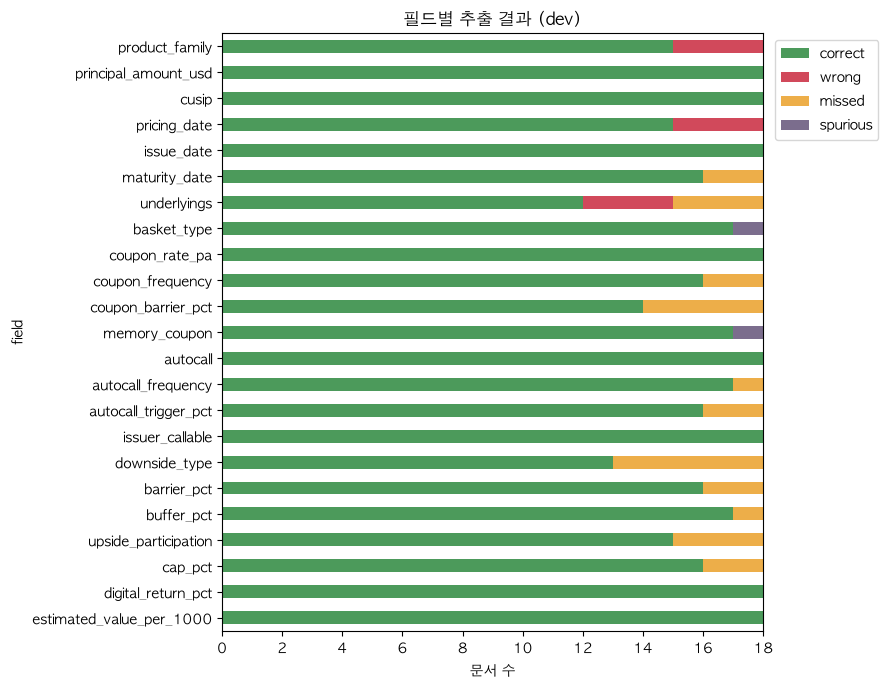

In [9]:
ax = dev_acc[["correct", "wrong", "missed", "spurious"]].plot(
    kind="barh", stacked=True, figsize=(9, 7), color=["#4c9a5b", "#d1495b", "#edae49", "#7b6d8d"],
    title="필드별 추출 결과 (dev)")
ax.invert_yaxis()
ax.set_xlabel("문서 수")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## 6. 오류 분석

틀린 행을 모아 보면 **원인이 몇 가지로 묶입니다.** 하나씩 고치는 것보다 원인을 고치는 것이 효율적입니다.

In [10]:
errors = cmp[(cmp.split == "dev") & (cmp.outcome != "correct")].copy()
errors["gold"] = errors.gold.map(show)
errors["pred"] = errors.pred.map(show)
errors[["accession_number", "field", "outcome", "gold", "pred"]]

,accession_number,field,outcome,gold,pred
0,0001213900-26-091167,product_family,wrong,leveraged_buffer,other
6,0001213900-26-091167,underlyings,missed,MXEA(index),
19,0001213900-26-091167,upside_participation,missed,1.5,None
20,0001213900-26-091167,cap_pct,missed,0.213,None
28,0001213900-26-091449,maturity_date,missed,2028-08-22,None
32,0001213900-26-091449,coupon_frequency,missed,quarterly,None
33,0001213900-26-091449,coupon_barrier_pct,missed,0.7,None
36,0001213900-26-091449,autocall_frequency,missed,quarterly,None
37,0001213900-26-091449,autocall_trigger_pct,missed,1.0,None
39,0001213900-26-091449,downside_type,missed,barrier,None


| 원인 | 증상 | 해당 문서 |
|---|---|---|
| **Goldman 플랫폼 형식** (Medium-Term Notes, `… Notes due 2028 (Linked to …)`) | 상품명을 못 찾아 상품군·기초자산·참여율·상한이 연쇄적으로 누락 | 091167, 100493, 115430 |
| **Strike Date 우선** | 가격 확정일 대신 기준가 결정일을 잡음 | 025611, 115430, 117911 |
| **기초자산 이름 분리** | `Affirm Holdings, Inc.`가 쉼표에서 쪼개짐, `Dow Jones Industrial Average`를 지수로 인식 못 함 | 033472, 028580, 032407 |
| **결합 라벨** | `Interest Barrier / Trigger Value: 50.00%`처럼 두 항목을 한 줄에 표기 | 033472, 029282 |
| **Morgan Stanley 형식** | `Contingent Income Auto-Callable Securities`의 표 형식 일정·배리어 | 091449 |

> **과적합 주의**: 특정 문서 번호를 코드에 넣거나 한 문서의 문구만 맞추는 규칙은 dev 점수만 올리고 실전 성능은 떨어뜨립니다. 원인 단위로 고치고, 마지막에 test 세트로 확인합니다.

In [11]:
test_score = (cmp[cmp.split == "test"].outcome == "correct").mean()
print(f"test 정확도 (기준선): {test_score:.1%}  ← 개선 후 마지막에 한 번만 다시 봅니다")

test 정확도 (기준선): 96.6%  ← 개선 후 마지막에 한 번만 다시 봅니다


## 7. 확정본 전체 추출

모듈 1 표본의 확정본 전체에 추출기를 돌려 저장합니다. 모듈 3에서 이 파일로 상품 DB를 만듭니다.

In [12]:
sample = pd.read_parquet(INTERIM_DIR / "filings_sample.parquet")
finals = sample[~sample.is_preliminary]

records = []
for r in tqdm(finals.itertuples(), total=len(finals), desc="추출"):
    ts = extract(r.text, r.accessionNumber)
    rec = ts.model_dump()
    rec["underlyings"] = json.dumps([u for u in rec["underlyings"]], ensure_ascii=False)
    rec["filing_date"] = r.filingDate
    rec["url"] = r.url
    records.append(rec)
termsheets = pd.DataFrame(records)
termsheets.to_parquet(INTERIM_DIR / "termsheets.parquet", index=False)
print(f"{len(termsheets)}건 저장 → {INTERIM_DIR / 'termsheets.parquet'}")
termsheets.product_family.value_counts()

추출:   0%|          | 0/150 [00:00<?, ?it/s]

추출:   7%|▋         | 11/150 [00:00<00:01, 104.36it/s]

추출:  15%|█▍        | 22/150 [00:00<00:01, 106.56it/s]

추출:  23%|██▎       | 34/150 [00:00<00:01, 106.07it/s]

추출:  31%|███       | 46/150 [00:00<00:00, 108.21it/s]

추출:  38%|███▊      | 57/150 [00:00<00:00, 103.84it/s]

... (7 outputs left out)

추출:  97%|█████████▋| 146/150 [00:01<00:00, 104.13it/s]

추출: 100%|██████████| 150/150 [00:01<00:00, 103.12it/s]

150건 저장 → /Users/joocheol/Documents/GitHub/AIFinance/data/interim/termsheets.parquet


product_family
autocall_contingent_coupon       43
autocall_call_premium            24
other                            20
issuer_call_contingent_coupon    18
leveraged_buffer                 13
digital                          12
dual_directional                 11
leveraged_barrier                 9
Name: count, dtype: int64

In [13]:
# 필드별 채움률: 상품군에 따라 원래 비어야 하는 필드(예: 버퍼 상품의 쿠폰)도 있으므로 상품군별로 봅니다
fill = termsheets.groupby("product_family")[["coupon_rate_pa", "coupon_barrier_pct", "autocall_trigger_pct",
                                              "barrier_pct", "buffer_pct", "upside_participation", "cap_pct",
                                              "estimated_value_per_1000"]].agg(lambda s: s.notna().mean())
fill.style.format("{:.0%}").background_gradient(cmap="Greens", vmin=0, vmax=1)

,coupon_rate_pa,coupon_barrier_pct,autocall_trigger_pct,barrier_pct,buffer_pct,upside_participation,cap_pct,estimated_value_per_1000
product_family,,,,,,,,
autocall_call_premium,0%,0%,79%,50%,50%,33%,0%,100%
autocall_contingent_coupon,74%,35%,67%,63%,16%,14%,0%,100%
digital,0%,0%,0%,42%,50%,0%,0%,100%
dual_directional,0%,0%,0%,18%,82%,36%,64%,100%
issuer_call_contingent_coupon,100%,67%,0%,78%,17%,0%,0%,100%
leveraged_barrier,0%,0%,0%,56%,0%,100%,0%,100%
leveraged_buffer,0%,0%,0%,0%,100%,85%,38%,100%
other,15%,0%,0%,5%,25%,20%,0%,90%


## 🤖 Claude 실습 2

**2-A. 정답셋 독립 검수** (사람 + Claude 교차 확인)
> `gold/manifest.csv`의 test 세트에서 3건을 골라, 기존 `gold/*.json`을 보지 말고 `data/text/`의 원문만 읽어 `prompts/gold_labeling.md` 지침대로 다시 라벨링해줘. 결과를 `scratch/` 폴더에 저장한 뒤 기존 정답과 필드별로 비교하고, 다른 항목은 원문 근거와 함께 어느 쪽이 맞는지 판정해줘.

**2-B. 추출기 개선 루프**
> `src/aifinance/extract.py`를 개선해줘. 규칙:
> 1. `gold/manifest.csv`의 **dev 세트만** 보고 오류를 원인별로 묶은 뒤, 원인 하나씩 고쳐.
> 2. 문서 번호를 코드에 넣지 마. 특정 문서 한 건만 맞추는 규칙도 금지.
> 3. 원인 하나를 고칠 때마다 dev 정확도를 다시 재서 표로 기록해. 이전에 맞던 필드가 틀려지면 되돌려.
> 4. 다 끝나면 test 정확도를 **한 번만** 측정해서 기준선(노트북 02)과 비교해줘.

**2-C. 판매사 플랫폼 형식 지원**
> 모듈 1 표본에서 상품명 추출에 실패한 확정본들을 찾아 어떤 형식(UBS의 Trigger GEARS·Trigger Step, Goldman 형식의 Medium-Term Notes 등)인지 분류해줘. 형식별로 판별 함수를 만들고, 가장 많은 형식부터 추출 규칙을 추가해줘. 형식별 건수도 표로 보여줘. JPM이 어느 판매사 플랫폼에 상품을 많이 공급하는지가 모듈 6의 분석 주제가 됩니다.

**2-D. 스키마 확장 제안**
> 정답셋을 만들며 스키마에 칸이 없던 정보(회차별 상환 프리미엄, 계단식 조기상환 기준, 버퍼 초과 손실 배수, 예비본의 "at least" 쿠폰 하한)를 `TermSheet`에 어떻게 넣을지 설계안을 제시해줘. 필드 이름, 타입, 예시 값을 표로 보여주고, 상품 분석에 각 필드가 왜 필요한지도 설명해줘.

---
**다음 모듈**: 모듈 3에서는 추출 결과로 DuckDB 상품 DB를 설계합니다. 예비본–확정본 병합, 공시 1건에 상품 여러 개가 들어 있는 경우 처리, 품질 점검 규칙이 핵심입니다.